# Exercises week 36

**FYS-STK3155/4155, fall 2026 — deadline Friday September 4 at midnight.**

The aim this week is that you own the two central results of Monday's lecture
— the statistics of the OLS estimator and the bias-variance decomposition,
Eq. (2.52) of the book — and the two resampling tools, the bootstrap and
$k$-fold cross-validation. The code you developed in the Tuesday session
(`week36tuesday.ipynb`) is meant to be reused here, and everything in this set
is directly reusable in Project 1.

Reading: Chapter 2, Sections 2.3–2.12 of the book; Hastie et al., Sections
7.1–7.5, 7.10 and 7.11.

## Exercise 1: Analytical exercises — the statistics of the OLS estimator

Assume the data are generated by the linear model of Eq. (2.37),
$\boldsymbol{y} = \boldsymbol{X}\boldsymbol{\theta} + \boldsymbol{\varepsilon}$,
with independent noise $\varepsilon_i \sim \mathcal{N}(0, \sigma^2)$ and a
fixed (non-stochastic) design matrix $\boldsymbol{X}$ of dimension $n \times p$.

**1a)** Show that the expectation value and variance of a single output are
(Eq. (2.39))

$$
\mathbb{E}[y_i] = \boldsymbol{X}_{i,*}\,\boldsymbol{\theta},
\qquad
\mathrm{Var}(y_i) = \sigma^2 .
$$

**1b)** Show that the OLS estimator is unbiased,
$\mathbb{E}[\hat{\boldsymbol{\theta}}] = \boldsymbol{\theta}$ (Eq. (2.45)), and
derive its variance (Eq. (2.47)),

$$
\mathrm{Var}(\hat{\boldsymbol{\theta}}) = \sigma^2\left(\boldsymbol{X}^T\boldsymbol{X}\right)^{-1}.
$$

*Hint:* use
$\mathbb{E}[\boldsymbol{y}\boldsymbol{y}^T] = \boldsymbol{X}\boldsymbol{\theta}\boldsymbol{\theta}^T\boldsymbol{X}^T + \sigma^2\boldsymbol{I}_{nn}$.

**1c)** Optional: Explain how the diagonal elements of
$\sigma^2(\boldsymbol{X}^T\boldsymbol{X})^{-1}$ give a confidence interval for
the coefficient $\theta_j$ (Eq. (2.48)), and why in practice $\sigma^2$ is
replaced by
$\hat{\sigma}^2 = \|\boldsymbol{y}-\boldsymbol{X}\hat{\boldsymbol{\theta}}\|_2^2/(n-p)$.
Where does the $n-p$ come from? (Think of Bessel's correction, Eq. (2.28).)

## Exercise 2: Analytical exercises — deriving the bias-variance tradeoff

Assume now, as in Section 2.10, that the true data are generated by
$\boldsymbol{y} = f(\boldsymbol{x}) + \boldsymbol{\varepsilon}$ with
$\boldsymbol{\varepsilon} \sim \mathcal{N}(0, \sigma^2)$ (Eq. (2.49)), and let
$\tilde{\boldsymbol{y}}$ be the prediction of a model fitted on a randomly
drawn training set.

**2a)** Starting from the expected squared error
$\mathbb{E}[(\boldsymbol{y}-\tilde{\boldsymbol{y}})^2]$ and adding and
subtracting $\mathbb{E}[\tilde{\boldsymbol{y}}]$, derive the decomposition of
Eq. (2.52),

$$
\mathbb{E}\left[(\boldsymbol{y}-\tilde{\boldsymbol{y}})^2\right]
= \frac{1}{n}\sum_i\left(f_i-\mathbb{E}[\tilde{\boldsymbol{y}}]\right)^2
+ \frac{1}{n}\sum_i\left(\tilde{y}_i-\mathbb{E}[\tilde{\boldsymbol{y}}]\right)^2
+ \sigma^2 .
$$

Show explicitly that all three cross terms vanish, stating for each one which
assumption kills it (zero-mean noise, independence of noise and training set,
$f$ non-stochastic).

**2b)** Explain in your own words what the expectation
$\mathbb{E}[\cdot]$ runs over, and what each of the three terms means for the
polynomial-fit example of the lecture.

**2c)** In the numerical estimate (Tuesday's Case 1) the bias is computed
against $y_{\mathrm{test}}$ rather than the unknown $f$. Show that the
measured "bias" then contains $\sigma^2$, so the printed identity
`error >= bias + variance` is an inequality.

## Exercise 3: The bias-variance tradeoff with the bootstrap

We use the same data as in the Tuesday session (and as in last week's
exercise 3),

$$
y = e^{-x^2} + 1.5\,e^{-(x-2)^2} + \varepsilon,
\qquad \varepsilon \sim \mathcal{N}(0, 0.1^2),
$$

on $x \in [-3, 3]$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.utils import resample

np.random.seed(2026)
n = 40
x = np.linspace(-3, 3, n).reshape(-1, 1)
y = np.exp(-x**2) + 1.5 * np.exp(-(x - 2)**2) + np.random.normal(0, 0.1, x.shape)


1. Split the data in training and test parts (80/20). For polynomial degrees
   $0$ to $13$, use the bootstrap (100 resamples of the training data) to
   estimate the test error, the squared bias and the variance, and plot the
   three curves as functions of the degree (compare with
   `week36_bias_variance.pdf` from the lecture — with seed 2026 you should
   reproduce it).
2. Discuss the figure in terms of Eq. (2.52): where is the model dominated by
   bias, where by variance, and where would you place the optimal degree?
3. Repeat the analysis for $n = 100$ and $n = 400$ data points and comment on
   how the curves and the optimal degree move.
4. Replace OLS by Ridge regression at a fixed high degree (say 12) and study
   the three terms as functions of $\lambda$ (for example
   `np.logspace(-6, 2, 9)`). Which term does $\lambda$ attack, and at what
   cost?

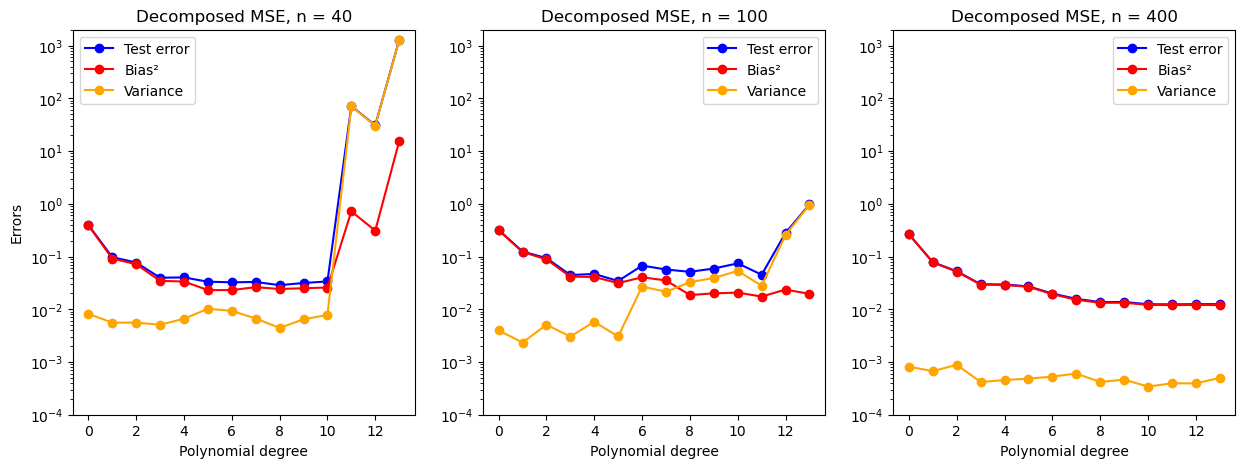

For n = 40: The test error is the bias² + variance. The model is dominated by the bias in low degrees of polynomial, up to degree 10, so 0-10. 
 At degree 11 and higher, the model is dominated by the variance.  The model has a broad minimum, so the optimal degree could be 6-10, but we would choose degree 8. 


With higher n, the variance decreases, and the test error and the bias become almost identical at very high n. The bias does not change that much between n=100 and n=400. The minimum moves towards higher polynomial degrees.


In [2]:
# Your code for exercise 3 here
n_bootstraps = 100 #100 resamples of training data
degree_max = 14 #13 + 1



def bootstrap_polynomial(n,degree_max):
    np.random.seed(2026)
    #n = 40
    x = np.linspace(-3, 3, n).reshape(-1, 1)
    y = np.exp(-x**2) + 1.5 * np.exp(-(x - 2)**2) + np.random.normal(0, 0.1, x.shape)


    x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2,
                                                        random_state=2026)


    #Create empty matrices
    error = np.zeros(degree_max)
    bias = np.zeros(degree_max)
    variance = np.zeros(degree_max)

    #Loop through the polynomial degrees
    for degree in range(degree_max):

        #Create a model 
        model = make_pipeline(PolynomialFeatures(degree=degree),
                              LinearRegression(fit_intercept=False))
        #Create empty matrix
        y_pred = np.empty((y_test.shape[0], n_bootstraps))
        #Loop through the resampling (bootstrapping)
        for i in range(n_bootstraps):
            x_, y_ = resample(x_train, y_train)
            y_pred[:, i] = model.fit(x_, y_).predict(x_test).ravel()

        error[degree] = np.mean(np.mean((y_test - y_pred)**2, axis=1, keepdims=True))
        bias[degree] = np.mean((y_test - np.mean(y_pred, axis=1, keepdims=True))**2)
        variance[degree] = np.mean(np.var(y_pred, axis=1, keepdims=True))

    return error, bias, variance
    

fig, ax = plt.subplots(1,3,figsize=[15,5])
sp = 0 #What subplot / axis to plot

for n in (40,100,400):
    error, bias, variance = bootstrap_polynomial(n,degree_max)

    #Plot results
    ax[sp].plot(range(degree_max),error,"o-",color="blue",label="Test error")
    ax[sp].plot(range(degree_max),bias,"o-",color="red", label="Bias²")
    ax[sp].plot(range(degree_max),variance,"o-",color="orange",label="Variance")
    ax[sp].set_title(f"Decomposed MSE, n = {n}")
    ax[sp].set_xlabel("Polynomial degree")
    
    ax[sp].set_ylim(1e-4,2e3)
    ax[sp].set_yscale("log")
    ax[sp].legend()
    sp += 1
ax[0].set_ylabel("Errors")
plt.show()


print("For n = 40: The test error is the bias² + variance. The model is dominated by the bias in low degrees of polynomial, up to degree 10, so 0-10. \n At degree 11 and higher, the model is dominated by the variance.  The model has a broad minimum, so the optimal degree could be 6-10, but we would choose degree 8. ")
print("\n")
print("With higher n, the variance decreases, and the test error and the bias become almost identical at very high n. The bias does not change that much between n=100 and n=400. The minimum moves towards higher polynomial degrees.")

In [3]:
#Replacing OLS by Ridge regression at fixed degree 12
def bias_variance_sweep(n=40, noise=0.1, maxdegree=14, n_bootstraps=100,
                        make_model=None, seed=2026):
    """Bootstrap estimate of error/bias^2/variance vs polynomial degree."""
    if make_model is None:
        make_model = lambda deg: make_pipeline(
            PolynomialFeatures(degree=deg), LinearRegression(fit_intercept=False))
    np.random.seed(seed)
    x = np.linspace(-3, 3, n).reshape(-1, 1)
    y = np.exp(-x**2) + 1.5 * np.exp(-(x - 2)**2) + np.random.normal(0, noise, x.shape)
    x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2,
                                                        random_state=seed)
    error, bias, variance = (np.zeros(maxdegree) for _ in range(3))
    for degree in range(maxdegree):
        model = make_model(degree)
        y_pred = np.empty((y_test.shape[0], n_bootstraps))
        for i in range(n_bootstraps):
            x_, y_ = resample(x_train, y_train)
            y_pred[:, i] = model.fit(x_, y_).predict(x_test).ravel()
        error[degree] = np.mean(np.mean((y_test - y_pred)**2, axis=1, keepdims=True))
        bias[degree] = np.mean((y_test - np.mean(y_pred, axis=1, keepdims=True))**2)
        variance[degree] = np.mean(np.var(y_pred, axis=1, keepdims=True))
    return error, bias, variance



degree_fixed = 12
lams = [0.0, 1e-4, 1e-1, 10.0]

print(f"degree {degree_fixed}, n = 40, 100 bootstraps")
print(f"{'lambda':>8}  {'error':>10}  {'bias^2':>10}  {'variance':>10}")
for lam in lams:
    if lam == 0.0:
        mk = lambda deg: make_pipeline(PolynomialFeatures(degree=deg),
                                       LinearRegression(fit_intercept=False))
    else:
        mk = lambda deg, lam=lam: make_pipeline(PolynomialFeatures(degree=deg),
                                                StandardScaler(),
                                                Ridge(alpha=lam))
    err, b2, var = bias_variance_sweep(n=40, maxdegree=degree_fixed + 1,
                                       make_model=mk)
    
    d = degree_fixed
    label = "OLS" if lam == 0.0 else f"{lam:g}"
    print(f"{label:>8}  {err[d]:10.4f}  {b2[d]:10.4f}  {var[d]:10.4f}")
    
    
print("The greater the lambda the greater the bias, which increases \n the error. What is interesting is that it does not affect the variance as much. \n The variance is consistently small with Ridge and much bigger with OLS.")

degree 12, n = 40, 100 bootstraps
  lambda       error      bias^2    variance
     OLS     30.8046      0.3090     30.4956
  0.0001      0.0338      0.0272      0.0067
     0.1      0.0289      0.0228      0.0060
      10      0.1020      0.0979      0.0041
The greater the lambda the greater the bias, which increases 
 the error. What is interesting is that it does not affect the variance as much. 
 The variance is consistently small with Ridge and much bigger with OLS.


## Exercise 4: Cross-validation

Still with the same type of data, we now select models without consuming a
test set.

1. Use scikit-learn's (or perhaps write your own) $k$-fold cross-validation function: shuffle the data,
   split into $k$ folds, use each fold as test set once, and return the mean
   and standard deviation over folds of the test MSE. Do **not** use
   `cross_val_score` inside your own function.
2. Use it with $k = 5$ to compute the CV estimate of the MSE for OLS with
   polynomial degrees $0$ to $13$, and compare with the bootstrap analysis of
   exercise 3: do the two methods point to the same degree window?
3. For a degree-6 polynomial with Ridge regression on
   $y = 3x^2 + \varepsilon$, $\varepsilon \sim \mathcal{N}(0,1)$, $n=100$
   (Tuesday's Case 2), compute the CV MSE on
   `np.logspace(-3, 5, 100)` and find the optimal $\lambda$. Any
   scaling/preprocessing must be fitted **inside** each fold — explain in one
   or two sentences why.
4. Try $k = 5, 10$ and $n$ (leave-one-out). Comment on the stability of the
   selected $\lambda$ and on the computational cost.

CV selects degree 5 (CV-MSE 7.8291)


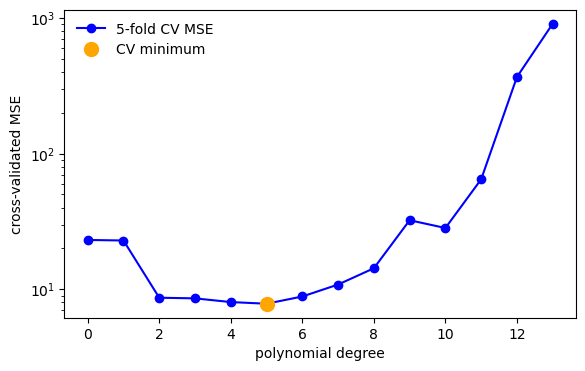

The two methods point to the same degree window.


In [4]:
#1: Using scikit-learns "KFold" function to shuffle the data and split into k folds
rng = np.random.default_rng(2026)
n = 100
x = rng.standard_normal(n)
y = 3 * x**2 + rng.standard_normal(n)     # noise variance is 1

nlambdas = 100
lambdas = np.logspace(-3, 5, nlambdas)
k = 5

def CV_models(k, degrees):
    np.random.seed(2026)
    kfold = KFold(n_splits=k, shuffle=True, random_state=2026)
    poly = PolynomialFeatures(degree=degrees)

    scores_KFold = np.zeros((nlambdas, k))
    for i, lmb in enumerate(lambdas):
        for j, (train_inds, test_inds) in enumerate(kfold.split(x)):
            xtrain, ytrain = x[train_inds], y[train_inds]
            xtest, ytest = x[test_inds], y[test_inds]

            Xtrain = poly.fit_transform(xtrain[:, np.newaxis])
            Xtest = poly.transform(xtest[:, np.newaxis])
            scaler = StandardScaler().fit(Xtrain)   # fitted on the training folds only

            ridge = Ridge(alpha=lmb)
            ridge.fit(scaler.transform(Xtrain), ytrain)
            ypred = ridge.predict(scaler.transform(Xtest))
            scores_KFold[i, j] = np.mean((ypred - ytest)**2)
    mse_KFold = np.mean(scores_KFold, axis=1) 
    return mse_KFold



#2. K =5 compute the CV estimate with 0-13 polynomial degrees
np.random.seed(2026)
n = 40
x1 = np.linspace(-3, 3, n).reshape(-1, 1)
y1 = np.exp(-x1**2) + 1.5 * np.exp(-(x1 - 2)**2) + np.random.normal(0, 0.1, x1.shape)

maxdegree = 14
kf = KFold(n_splits=5, shuffle=True, random_state=2026)
mse_kfold = np.zeros(maxdegree)
for degree in range(maxdegree):
    mse_kfold[degree] = CV_models(k,degree).mean()

best_deg = np.argmin(mse_kfold)
print(f"CV selects degree {best_deg} (CV-MSE {mse_kfold[best_deg]:.4f})")

fig, ax = plt.subplots(figsize=(6.6, 4.0))
ax.plot(range(maxdegree), mse_kfold, "o-", color="blue", label="5-fold CV MSE")
ax.plot(best_deg, mse_kfold[best_deg], "o", color="orange", ms=10, label="CV minimum")
ax.set_yscale("log")
ax.set_xlabel("polynomial degree")
ax.set_ylabel("cross-validated MSE")
ax.legend(frameon=False)
plt.show()

print("The two methods point to the same degree window, with smaller MSE at lower polynomials and higher MSE as very high polynomials.")

In [5]:


#3. degree-6 polynomial with Ridge regression, computing CV MSE and finding the optimal lambda.

for k in [5,10]:
    mse_KFold = CV_models(k,6)
    best = np.argmin(mse_KFold)
    print(f"best lambda {lambdas[best]:.4g}, cross-validated MSE {mse_KFold[best]:.4f} when k = {k}")

n = 40
mse_KFold = CV_models(n,6)
best = np.argmin(mse_KFold)
print(f"best lambda {lambdas[best]:.4g}, cross-validated MSE {mse_KFold[best]:.4f}  when k = {n}")
    
    
print("The scaling/preprocessing must be fitted inside each fold because the scaling depends on the values chosen for each fold. This is because the data needs to be preserved. If you scale it inside the fold, then the data preserves the shape.")

print("The lambdas does not change that much, so it is pretty stable. The same applies to the MSE. As it is stable with k, it is unecessary to increase the k and therefore the computational cost.")


best lambda 1.177, cross-validated MSE 1.4569 when k = 5
best lambda 2.057, cross-validated MSE 1.4708 when k = 10
best lambda 2.477, cross-validated MSE 1.3571  when k = 40
The scaling/preprocessing must be fitted inside each fold because the scaling depends on the values chosen for each fold. This is because the data needs to be preserved. If you scale it inside the fold, then the data preserves the shape.
The lambdas does not change that much, so it is pretty stable. The same applies to the MSE. As it is stable with k, it is unecessary to increase the k and therefore the computational cost.


## Exercise 5 (optional): error bars from the bootstrap

Use the bootstrap to attach uncertainties to fitted parameters, where the
analytical formula of exercise 1 can be checked — and where it cannot.

1. For OLS on a degree-3 polynomial fit of the exercise-3 data, bootstrap the
   training data 1000 times and histogram the resulting
   $\hat{\theta}_j^*$. Compare the bootstrap standard deviations with the
   analytical standard errors
   $\hat{\sigma}\sqrt{[(\boldsymbol{X}^T\boldsymbol{X})^{-1}]_{jj}}$ of
   Eq. (2.48).
2. Repeat for Lasso with a small penalty. Why is the bootstrap now the only
   option on the table? (Which assumption behind Eq. (2.48) fails?)

In [6]:
# Your code for exercise 5 here

### Practicalities

Deliver your solutions (a single Jupyter notebook, with the analytical parts
either typeset in Markdown/LaTeX or as a scanned handwritten note) in Canvas
before **Friday September 4 at midnight**. Collaboration is encouraged — list
your collaborators.